# House Prices — XGBoost trên 5 bộ đặc trưng sau lọc ngoại lệ

So sánh trên cùng 5 fold và siêu tham số cố định. Quy tắc chọn sau khi xem dữ liệu gốc đánh dấu các căn có GrLivArea > 4000 và SalePrice < 200000. Chỉ loại căn được đánh dấu khỏi phần huấn luyện của fold. Mọi căn đều được giữ để tính RMSE validation.

## Tham số cố định

In [1]:
EXPERIMENT_NAME = "15-11-2026_XGBoost_5bo_outlier_phuc"
RANDOM_STATE = 42
N_SPLITS = 5
MODEL_PARAMS = {
    "n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
    "random_state": RANDOM_STATE, "n_jobs": 2,
}
AREA_LIMIT = 4000
PRICE_LIMIT = 200000

## Import và kiểm tra kernel

In [2]:
from itertools import combinations
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

try:
    import xgboost
except ModuleNotFoundError as error:
    if error.name != "xgboost":
        raise
    raise ModuleNotFoundError(
        "Kernel chua co XGBoost. Chay %pip install xgboost-cpu roi Restart Kernel."
    ) from error

from src.model import make_xgboost
from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor

## Dữ liệu và tạo đặc trưng

- `TotalSF` cộng diện tích tầng hầm, tầng 1 và tầng 2.
- `TotalBath` cộng phòng tắm đầy đủ ở phần trên mặt đất và tầng hầm. Mỗi nửa phòng tắm tính 0,5.
- `AgeAtSale` lấy năm bán trừ năm xây.

Các phép tính dùng dữ liệu của từng căn nhà. Pipeline điền thiếu, chuẩn hóa và mã hóa được fit trên phần train của từng fold.

In [3]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

formulas = {
    "TotalSF": "TotalBsmtSF + 1stFlrSF + 2ndFlrSF",
    "TotalBath": "FullBath + BsmtFullBath + 0.5 * (HalfBath + BsmtHalfBath)",
    "AgeAtSale": "YrSold - YearBuilt",
}
X_extra = X.assign(
    TotalSF=X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"],
    TotalBath=X["FullBath"] + X["BsmtFullBath"] + 0.5 * (X["HalfBath"] + X["BsmtHalfBath"]),
    AgeAtSale=X["YrSold"] - X["YearBuilt"],
)
assert X_extra.shape[1] == 82
display(X_extra[list(formulas)].describe().round(2))

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y, "fold": 0})
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold
baseline_dir = (project / "experiments" / "14-11-2026_6model_79_phuc"
                / "outputs" / "20261114_224507_500186")
baseline = pd.read_csv(baseline_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(baseline[[ID, "fold"]])
np.testing.assert_allclose(y, baseline["ln_SalePrice"])
suspect = train["GrLivArea"].gt(AREA_LIMIT) & prices.lt(PRICE_LIMIT)
suspected_outliers = train.loc[suspect, [ID, "GrLivArea", TARGET]].copy()
suspected_outliers["validation_fold"] = predictions.loc[suspect, "fold"]
display(suspected_outliers)

reference_dir = (project / "experiments" / "15-11-2026_XGBoost_cap_dac_trung_phuc"
                 / "outputs" / "20261115_094428_793379")
reference = pd.read_csv(reference_dir / "validation_metrics.csv").set_index("variant")
reference_predictions = pd.read_csv(reference_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(reference_predictions[[ID, "fold"]])


,TotalSF,TotalBath,AgeAtSale
count,1460.00,1460.00,1460.00
mean,2567.05,2.21,36.55
std,821.71,0.79,30.25
min,334.00,1.00,0.00
25%,2009.50,2.00,8.00
50%,2474.00,2.00,35.00
75%,3004.00,2.50,54.00
max,11752.00,6.00,136.00


,Id,GrLivArea,SalePrice,validation_fold
523,524,4676,184750,3
1298,1299,5642,160000,3


## Huấn luyện và so sánh

In [4]:
metric_rows = []
audit_rows = []
warning_rows = []
fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]
variants = {"79_goc": X}
feature_pairs = list(combinations(formulas, 2))
for pair in feature_pairs:
    variants[" + ".join(pair)] = X_extra.loc[:, [*X.columns, *pair]]
variants["82_ca_ba"] = X_extra

for name, features in variants.items():
    pipeline = make_pipeline(make_preprocessor(features), make_xgboost(**MODEL_PARAMS))
    scores = []
    started = perf_counter()
    for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
        kept = fit_idx[~suspect.iloc[fit_idx].to_numpy()]
        audit_rows.append({
            "variant": name, "fold": fold, "train_rows": len(kept),
            "validation_rows": len(valid_idx),
            "removed_ids": json.dumps(train.iloc[np.setdiff1d(fit_idx, kept)][ID].tolist()),
        })
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fitted = clone(pipeline).fit(features.iloc[kept], y.iloc[kept])
            predicted = fitted.predict(features.iloc[valid_idx])
        predictions.loc[valid_idx, f"xgboost_{name}"] = predicted
        scores.append(root_mean_squared_error(y.iloc[valid_idx], predicted))
        for item in caught:
            warning_rows.append({"features": name, "fold": fold,
                                 "category": item.category.__name__, "message": str(item.message)})
    metric_rows.append({
        "model": "XGBoost", "variant": name, "features": features.shape[1],
        **dict(zip(fold_columns, scores)),
        "rmse_log_mean": np.mean(scores), "rmse_log_std": np.std(scores, ddof=1),
        "elapsed_seconds": perf_counter() - started,
    })

assert predictions[[f"xgboost_{name}" for name in variants]].notna().all().all()
results = pd.DataFrame(metric_rows).set_index("variant")
comparison = results[fold_columns].subtract(reference[fold_columns])
comparison["rmse_before_filter"] = reference["rmse_log_mean"]
comparison["rmse_after_filter"] = results["rmse_log_mean"]
comparison["delta_mean"] = comparison["rmse_after_filter"] - comparison["rmse_before_filter"]
comparison["folds_improved"] = (comparison[fold_columns] < 0).sum(axis=1)
fit_audit = pd.DataFrame(audit_rows)
assert len(predictions) == len(train) and predictions.notna().all().all()
display(results.round(5))
display(comparison.sort_values("rmse_after_filter").round(5))

,model,features,fold1,fold2,fold3,fold4,fold5,rmse_log_mean,rmse_log_std,elapsed_seconds
variant,,,,,,,,,,
79_goc,XGBoost,79,0.13228,0.11216,0.16912,0.13406,0.11041,0.13161,0.02367,2.16592
TotalSF + TotalBath,XGBoost,81,0.13710,0.11221,0.16284,0.12474,0.11572,0.13052,0.02047,2.19891
TotalSF + AgeAtSale,XGBoost,81,0.13925,0.11014,0.16767,0.12677,0.11161,0.13109,0.02367,2.19218
TotalBath + AgeAtSale,XGBoost,81,0.13370,0.11195,0.16756,0.13160,0.11416,0.13179,0.02229,2.30048
82_ca_ba,XGBoost,82,0.13808,0.11146,0.16862,0.12517,0.11407,0.13148,0.02327,2.13285


,fold1,fold2,fold3,fold4,fold5,rmse_before_filter,rmse_after_filter,delta_mean,folds_improved
variant,,,,,,,,,
TotalSF + TotalBath,-0.00230,-0.00780,0.0,-0.00351,-0.00073,0.13339,0.13052,-0.00287,4
TotalSF + AgeAtSale,0.00045,-0.00700,0.0,-0.00018,-0.00055,0.13255,0.13109,-0.00146,3
82_ca_ba,-0.00043,-0.00683,0.0,-0.00276,-0.00349,0.13418,0.13148,-0.00270,4
79_goc,-0.00050,-0.00623,0.0,-0.00007,-0.00270,0.13351,0.13161,-0.00190,4
TotalBath + AgeAtSale,-0.00009,-0.00678,0.0,0.00082,-0.00229,0.13346,0.13179,-0.00167,3


## Biểu đồ và nhận xét

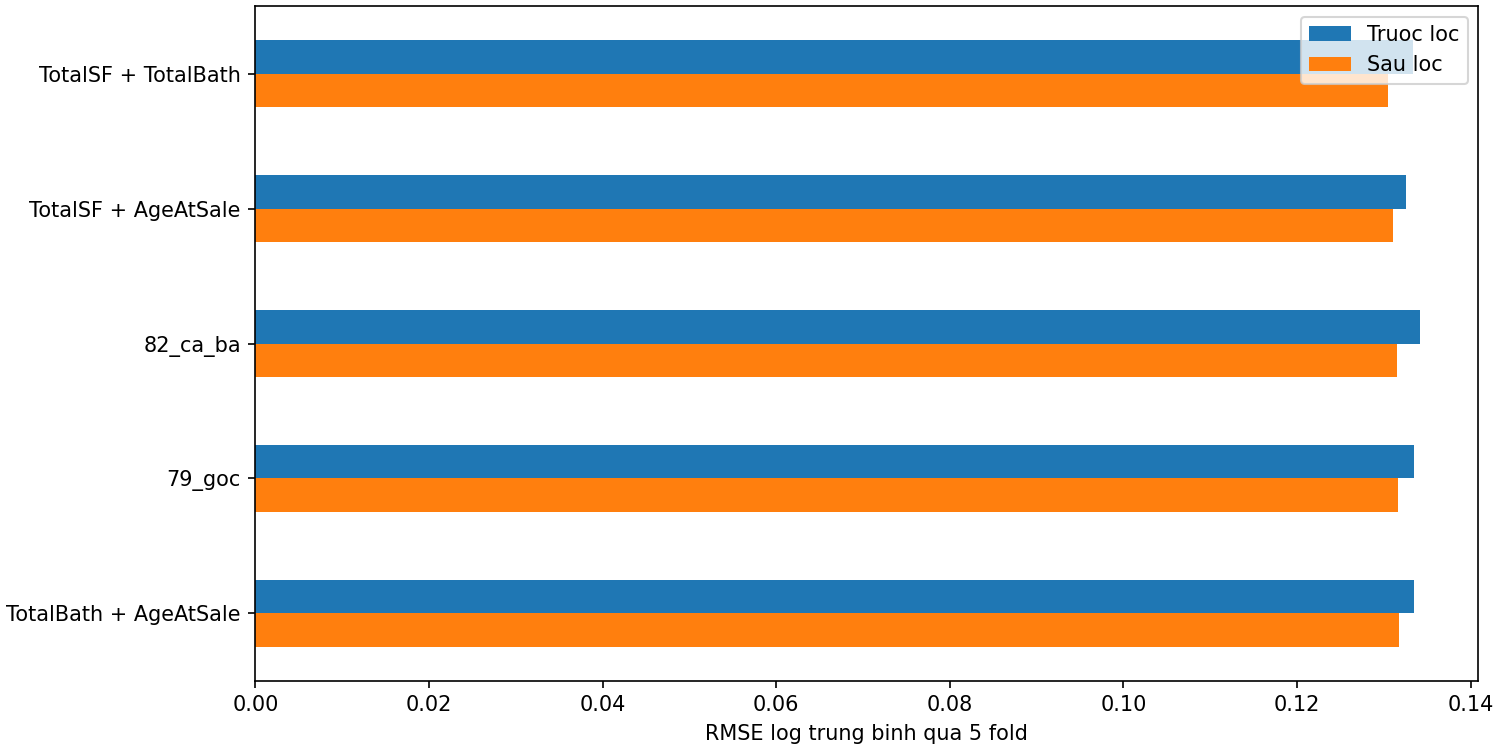

In [5]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
comparison[["rmse_before_filter", "rmse_after_filter"]].sort_values(
    "rmse_after_filter"
).rename(columns={
    "rmse_before_filter": "Truoc loc", "rmse_after_filter": "Sau loc",
}).plot.barh(ax=ax)
ax.invert_yaxis()
ax.set(xlabel="RMSE log trung binh qua 5 fold", ylabel="")
plt.show()

## Lưu kết quả

In [6]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
image_dir = run_dir / "img"
image_dir.mkdir(parents=True, exist_ok=False)
results.to_csv(run_dir / "validation_metrics.csv")
comparison.to_csv(run_dir / "comparison_outliers.csv", index_label="variant")
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
pd.DataFrame(warning_rows, columns=["features", "fold", "category", "message"]).to_csv(
    run_dir / "validation_warnings.csv", index=False
)
config = {
    "dataset": "data/raw/train.csv", "target_transform": "natural log",
    "baseline": str(baseline_dir.relative_to(project)), "feature_formulas": formulas, "feature_pairs": feature_pairs,
    "cv": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE},
    "outlier_rule": {"GrLivArea_gt": AREA_LIMIT, "SalePrice_lt": PRICE_LIMIT, "scope": "fold train only"},
    "reference": str(reference_dir.relative_to(project)),
    "model_params": MODEL_PARAMS, "xgboost_version": xgboost.__version__,
}
(run_dir / "manual_params.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(image_dir / "outlier_comparison.png", dpi=150)
print(run_dir.relative_to(project))
suspected_outliers.to_csv(run_dir / "suspected_outliers.csv", index=False)
fit_audit.to_csv(run_dir / "filter_audit.csv", index=False)

experiments\15-11-2026_XGBoost_5bo_outlier_phuc\outputs\20261115_104726_284284
